In [1]:
import sys
print(sys.executable)

C:\Users\chami\sepsis-early-warning\.venv\Scripts\python.exe


In [2]:
import sys
sys.path.append("..")
from pathlib import Path
import duckdb, numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.evaluate import add_onset, bootstrap_metrics, threshold_table, calibration

ROOT = Path("..").resolve()
PRED = ROOT / "data" / "predictions"
con = duckdb.connect(str(ROOT / "data" / "sepsis.duckdb"), read_only=True)
cohort = con.execute("SELECT patient_id, septic, onset_iculos FROM cohort WHERE included").df()
con.close()

def load(name):
    return add_onset(pd.read_parquet(PRED / f"{name}_val.parquet"), cohort)

main = load("lgbm")
no_ord = load("lgbm-ordering")
weighted = load("lgbm+weighted")
print(len(main), len(no_ord), len(weighted))   # should all be 119,450

119450 119450 119450


In [3]:
rows = []
for name, d in [("main (with ordering)", main), ("without ordering", no_ord)]:
    for scope, sub in [("all hours", d), ("pre-onset hours", d[d["pre_onset"]])]:
        m = bootstrap_metrics(sub["y"], sub["p"], sub["patient_id"], n_boot=200)
        rows.append({"model": name, "scope": scope,
                     **{k: f"{v[0]:.3f} ({v[1]:.3f}–{v[2]:.3f})" for k, v in m.items()}})
pd.DataFrame(rows)

,model,scope,auroc,auprc
0,main (with ordering),all hours,0.809 (0.785–0.831),0.083 (0.069–0.103)
1,main (with ordering),pre-onset hours,0.790 (0.763–0.813),0.046 (0.038–0.057)
2,without ordering,all hours,0.799 (0.767–0.826),0.076 (0.064–0.095)
3,without ordering,pre-onset hours,0.781 (0.747–0.809),0.044 (0.037–0.054)


In [4]:
thresholds = [0.02, 0.03, 0.05, 0.08, 0.10, 0.15, 0.20, 0.30]
tt_main = threshold_table(main, thresholds)
tt_main.round(3)

,threshold,early_sensitivity,median_lead_h,alerts_per_100_patient_days,alert_ppv,nonseptic_patients_alerted
0,0.02,0.773,9.0,111.491,0.079,0.398
1,0.03,0.672,9.0,76.792,0.098,0.285
2,0.05,0.496,8.0,43.600,0.123,0.166
3,0.08,0.349,8.0,24.050,0.150,0.092
4,0.10,0.273,8.0,17.058,0.171,0.061
5,0.15,0.181,8.0,8.439,0.198,0.026
6,0.20,0.122,7.0,5.083,0.209,0.013
7,0.30,0.017,7.0,1.869,0.161,0.005


In [5]:
tt_no = threshold_table(no_ord, thresholds)
tt_no.round(3)

,threshold,early_sensitivity,median_lead_h,alerts_per_100_patient_days,alert_ppv,nonseptic_patients_alerted
0,0.02,0.752,9.0,113.781,0.078,0.391
1,0.03,0.647,8.0,75.828,0.095,0.283
2,0.05,0.466,8.0,42.073,0.122,0.155
3,0.08,0.324,8.0,22.744,0.146,0.082
4,0.10,0.273,7.0,16.114,0.161,0.058
5,0.15,0.155,7.0,7.494,0.190,0.024
6,0.20,0.084,4.5,4.219,0.195,0.012
7,0.30,0.025,6.0,1.366,0.176,0.004


unweighted (main): mean predicted 0.0178 vs actual positive rate 0.0193
class-weighted: mean predicted 0.2282 vs actual positive rate 0.0193


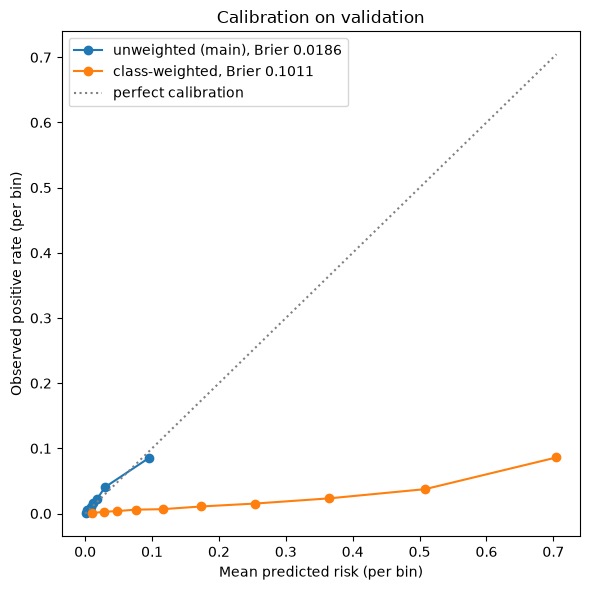

In [6]:
fig, ax = plt.subplots(figsize=(6, 6))
top = 0
for name, d in [("unweighted (main)", main), ("class-weighted", weighted)]:
    cal, brier = calibration(d["y"], d["p"])
    ax.plot(cal["mean_predicted"], cal["observed_rate"], marker="o", label=f"{name}, Brier {brier:.4f}")
    top = max(top, cal["mean_predicted"].max(), cal["observed_rate"].max())
    print(f"{name}: mean predicted {d['p'].mean():.4f} vs actual positive rate {d['y'].mean():.4f}")
ax.plot([0, top], [0, top], linestyle=":", color="gray", label="perfect calibration")
ax.set_xlabel("Mean predicted risk (per bin)")
ax.set_ylabel("Observed positive rate (per bin)")
ax.set_title("Calibration on validation")
ax.legend()
plt.tight_layout()
plt.show()